# AE 370 Group Project 1 — Fuel-optimal climb angle and cruise altitude

**Question.** For three fixed routes from Chicago O'Hare (ORD) — JFK (1,191 km), Copenhagen (6,873 km), Hong Kong (12,543 km) —
which flight-path angle $\gamma$ and cruise altitude $h_{cruise}$ minimize total fuel burned?

**Files.** `aircraft.py` holds the model and the from-scratch integrators: forward Euler, classical RK4, and a 4th-order Adams–Bashforth–Moulton predictor-corrector (PECE). This notebook holds only the studies.
No external time integrator is used anywhere.

**Model**
- State $[V,h,x,m]$; fixed $\gamma$ during climb, $\gamma=0$ in cruise; start at $h=0$.
- Speed schedule: the aircraft holds the **minimum-drag speed** at its current altitude and mass, capped at Mach 0.85.
  Thrust is commanded by a speed-hold law $T = D + mg\sin\gamma + mK(V_{target}-V)$, so $V$ stays a true state variable.
- Fuel flow is $T/(I_{sp}g_0)$ in both phases (cruise: $T\approx D$).
- A case is **masked** (infeasible) if at any time $T>T_{max}$, $C_L>C_{L,max}$, or the fuel is exhausted.
- Descent and landing are neglected. Takeoff mass is the same on every route.

In [7]:
import math, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from aircraft import *
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
P = dict(P_DEFAULT)
ROUTES = {"ORD-JFK": 1191e3, "ORD-CPH": 6873e3, "ORD-HKG": 12543e3}
print({k: P[k] for k in ("S","m0","m_dry","Isp","Tmax","CLmax","Mmax","Kspd")})

{'S': 550.0, 'm0': 400000.0, 'm_dry': 210000.0, 'Isp': 6000.0, 'Tmax': 600000.0, 'CLmax': 1.2, 'Mmax': 0.85, 'Kspd': 0.05}


## 1. Atmosphere and speed schedule

rho(0) = 1.2266 kg/m^3 (ISA: 1.2250; NASA fit is 0.1% high)
density jump across 11 km: -2.84e-07 (relative)


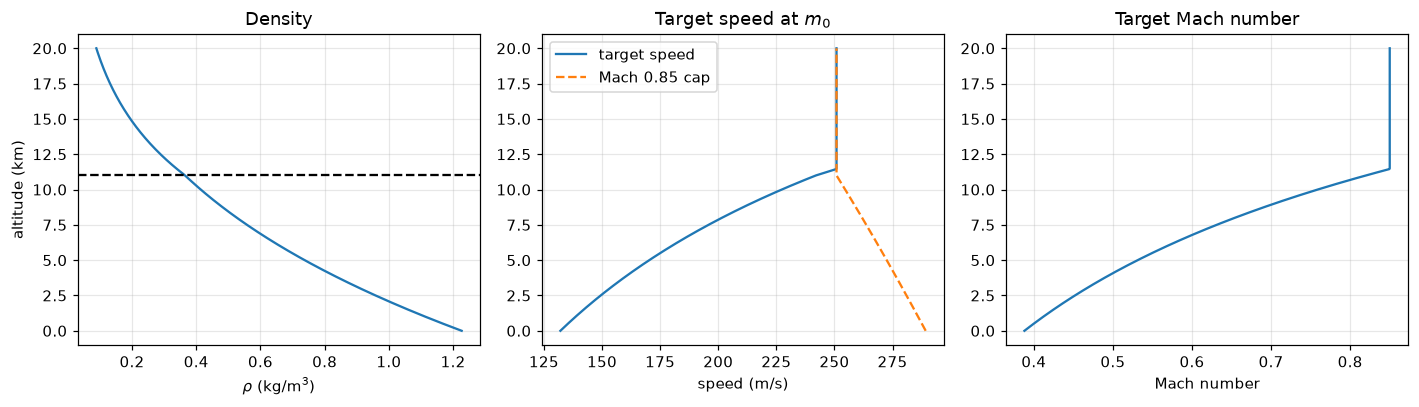

In [8]:
h = np.linspace(0, 20000, 401)
rho = np.array([atmosphere(x)[1] for x in h]); a = np.array([atmosphere(x)[2] for x in h])
Vt = np.array([target_speed(x, P["m0"], P) for x in h])
print("rho(0) = %.4f kg/m^3 (ISA: 1.2250; NASA fit is 0.1%% high)" % atmosphere(0)[1])
print("density jump across 11 km: %.2e (relative)" % ((atmosphere(11000.001)[1]-atmosphere(10999.999)[1])/atmosphere(11000)[1]))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(rho, h/1e3); ax[0].axhline(11, ls="--", c="k"); ax[0].set(xlabel=r"$\rho$ (kg/m$^3$)", ylabel="altitude (km)", title="Density")
ax[1].plot(Vt, h/1e3, label="target speed"); ax[1].plot(0.85*a, h/1e3, "--", label="Mach 0.85 cap")
ax[1].set(xlabel="speed (m/s)", title="Target speed at $m_0$"); ax[1].legend()
ax[2].plot(Vt/a, h/1e3); ax[2].set(xlabel="Mach number", title="Target Mach number")
plt.tight_layout(); plt.show()

## 2. Validation against exact solutions

Convergence alone cannot show the equations are right, so we compare against two closed-form special cases.

**Cruise.** At constant $h$ and $V$, $D = a + b m^2$ with $a=\tfrac12\rho V^2 S C_{D0}$, $b = 2kg_0^2/(\rho V^2 S)$, and
$\dot m = -(a+bm^2)/(I_{sp}g_0)$. This separates to
$m(t)=\sqrt{a/b}\,\tan\!\big[\arctan(m_0\sqrt{b/a})-\sqrt{ab}\,t/(I_{sp}g_0)\big]$.

**Linear climb limit.** With constant density, $k=0$ and fixed $V$, $D$ is constant and
$\dot m = -(D+mg_0\sin\gamma)/(I_{sp}g_0)$ is linear, with $m(t)=(m_0+d/c)e^{-ct}-d/c$,
$c=\sin\gamma/I_{sp}$, $d=D/(I_{sp}g_0)$.

cruise rk4 ['1.4e-05', '8.2e-07', '4.9e-08', '3.1e-09', '2.9e-10'] slopes [4.09 4.05 3.98 3.43]
climb limit rk4 ['3.9e+01', '2.2e+00', '1.3e-01', '7.8e-03', '4.8e-04'] slopes [4.16 4.08 4.04 4.02]


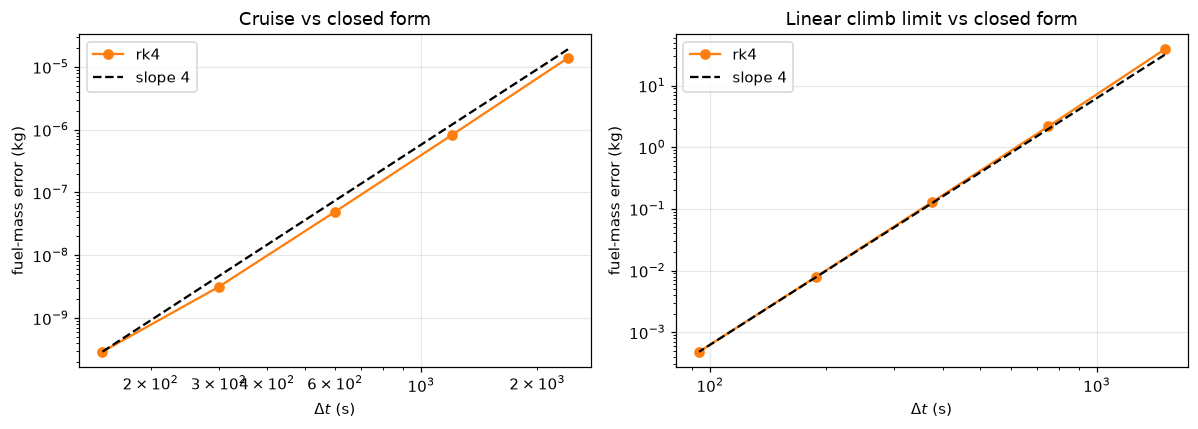

In [20]:
def run_fixed_time(y0, gam, T, dt, Pp, method):
    step = STEPPERS[method]; y = list(y0)
    for _ in range(int(round(T/dt))): y = step(y, dt, gam, Pp)
    return y

def slopes(dts, errs): return [math.log(errs[i]/errs[i+1])/math.log(dts[i]/dts[i+1]) for i in range(len(dts)-1)]

# --- cruise ---
Pc = {**P, "V_fixed": 250.0}; hc_, Vc_, m0c, Tc = 12000., 250., 400000., 4800.
rho_c = atmosphere(hc_)[1]
ac = 0.5*rho_c*Vc_**2*Pc["S"]*Pc["CD0"]; bc = 2*Pc["k"]*G0**2/(rho_c*Vc_**2*Pc["S"])
m_exact_c = math.sqrt(ac/bc)*math.tan(math.atan(m0c*math.sqrt(bc/ac)) - math.sqrt(ac*bc)*Tc/(Pc["Isp"]*G0))
cruise = {}
for meth, dts in (("rk4", [2400,1200,600,300,150]),):
    errs = [abs(run_fixed_time([Vc_,hc_,0,m0c], 0.0, Tc, dt, Pc, meth)[3] - m_exact_c) for dt in dts]
    cruise[meth] = (dts, errs); print("cruise", meth, ["%.1e"%e for e in errs], "slopes", np.round(slopes(dts, errs), 2))

# --- linear climb limit ---
Pl = {**P, "rho_const": 0.4, "k": 0.0, "V_fixed": 200.0, "Isp": 300.0, "Kspd": 1e-4}
gam_l = math.radians(3); m0l, Tl, Vl = 2.0e6, 6000., 200.
Dl = 0.5*0.4*Vl**2*Pl["S"]*Pl["CD0"]; cl = math.sin(gam_l)/Pl["Isp"]; dl = Dl/(Pl["Isp"]*G0)
m_exact_l = (m0l + dl/cl)*math.exp(-cl*Tl) - dl/cl
climb = {}
for meth, dts in (("rk4", [1500,750,375,187.5,93.75]),):
    errs = [abs(run_fixed_time([Vl,0,0,m0l], gam_l, Tl, dt, Pl, meth)[3] - m_exact_l) for dt in dts]
    climb[meth] = (dts, errs); print("climb limit", meth, ["%.1e"%e for e in errs], "slopes", np.round(slopes(dts, errs), 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, data, ttl in ((ax[0], cruise, "Cruise vs closed form"), (ax[1], climb, "Linear climb limit vs closed form")):
    for meth, (dts, errs) in data.items(): a_.loglog(dts, errs, "o-", color="tab:orange", label=meth)
    d1 = np.array(data["rk4"][0]); a_.loglog(d1, data["rk4"][1][-1]*(d1/d1[-1])**4, "k--", label="slope 4")
    a_.set(xlabel=r"$\Delta t$ (s)", ylabel="fuel-mass error (kg)", title=ttl); a_.legend()
plt.tight_layout(); plt.show()

## 4. Convergence of the full simulation (climb + cruise + both events)

Two cases, both $\gamma=3^\circ$, ORD–JFK. **Smooth case** ($h_{cruise}=10$ km): no kinks in the right-hand side, so the methods should show their full order.
**Kinked case** ($h_{cruise}=12$ km): the trip crosses the 11 km layer boundary (a slope discontinuity in $\rho(h)$) and, in cruise,
the target speed switches between the Mach cap and the min-drag speed (a kink in $\min(\cdot,\cdot)$). Both methods need a smooth right-hand side for
4th order, so the observed order is limited here. The multistep method also carries a short history across the kink.

For the predictor-corrector, each phase restarts with three RK4 steps and the landing step on each event is RK4.

Smooth case, $h_{cruise}$ = 10 km: reference fuel (RK4, dt=1/16 s) = 26271.2212 kg
  euler ['3.24e+01', '1.62e+01', '8.13e+00', '4.07e+00', '2.04e+00'] slopes [1. 1. 1. 1.]
  rk4   ['3.50e-04', '1.84e-05', '1.02e-06', '5.72e-08'] slopes [4.25 4.17 4.16]
  abm4  ['4.17e-04', '5.06e-05', '5.94e-06', '5.27e-07', '3.69e-08'] slopes [3.04 3.09 3.49 3.84]
Kinked case, $h_{cruise}$ = 12 km: reference fuel (RK4, dt=1/16 s) = 25123.9844 kg
  euler ['3.91e+01', '1.95e+01', '9.74e+00', '4.88e+00', '2.44e+00'] slopes [1. 1. 1. 1.]
  rk4   ['1.06e-02', '5.54e-03', '5.37e-04', '3.24e-04', '1.14e-04', '4.38e-05'] slopes [0.94 3.37 0.73 1.51 1.38]
  abm4  ['1.47e-01', '1.32e-02', '1.73e-03', '8.54e-04', '2.90e-05', '7.83e-05'] slopes [ 3.48  2.93  1.02  4.88 -1.43]


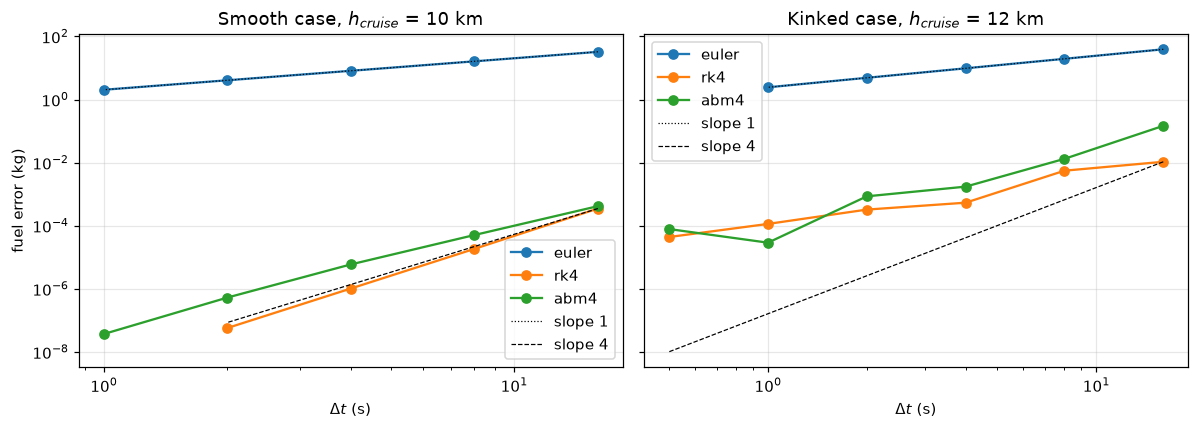

In [10]:
g0_, X0 = math.radians(3.0), ROUTES["ORD-JFK"]
CASES = {"smooth": (10000., "Smooth case, $h_{cruise}$ = 10 km", {"euler": [16,8,4,2,1], "rk4": [16,8,4,2], "abm4": [16,8,4,2,1]}),
         "kinked": (12000., "Kinked case, $h_{cruise}$ = 12 km", {"euler": [16,8,4,2,1], "rk4": [16,8,4,2,1,0.5], "abm4": [16,8,4,2,1,0.5]})}
DATA = {}
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a_, (key, (hc0, ttl, dtsets)) in zip(ax, CASES.items()):
    ref = fly(g0_, hc0, X0, dt_climb=0.0625, dt_cruise=0.0625, method="rk4")["fuel"]
    print(f"{ttl}: reference fuel (RK4, dt=1/16 s) = {ref:.4f} kg"); DATA[key] = {}
    for meth, dts in dtsets.items():
        runs = [fly(g0_, hc0, X0, dt_climb=d, dt_cruise=d, method=meth) for d in dts]
        errs = [abs(r["fuel"] - ref) for r in runs]; nf = [r["nfev"] for r in runs]
        DATA[key][meth] = (dts, errs, nf)
        print("  %-5s" % meth, ["%.2e" % e for e in errs], "slopes", np.round(slopes(dts, errs), 2))
        a_.loglog(dts, errs, "o-", label=meth)
    de = np.array(dtsets["euler"]); a_.loglog(de, DATA[key]["euler"][1][-1]*(de/de[-1]), "k:", lw=0.8, label="slope 1")
    dr = np.array(dtsets["rk4"]);   a_.loglog(dr, DATA[key]["rk4"][1][0]*(dr/dr[0])**4, "k--", lw=0.8, label="slope 4")
    a_.set(xlabel=r"$\Delta t$ (s)", title=ttl); a_.legend()
ax[0].set_ylabel("fuel error (kg)"); plt.tight_layout(); plt.show()

## 5. Cost: work–precision

The right-hand side (atmosphere, drag, thrust law) dominates run time, so we count its evaluations:
Euler 1 per step, RK4 4 per step, PECE 2 per step (plus a one-off start-up per phase). Event-location evaluations are
excluded because they are the same for every method at a given step size.

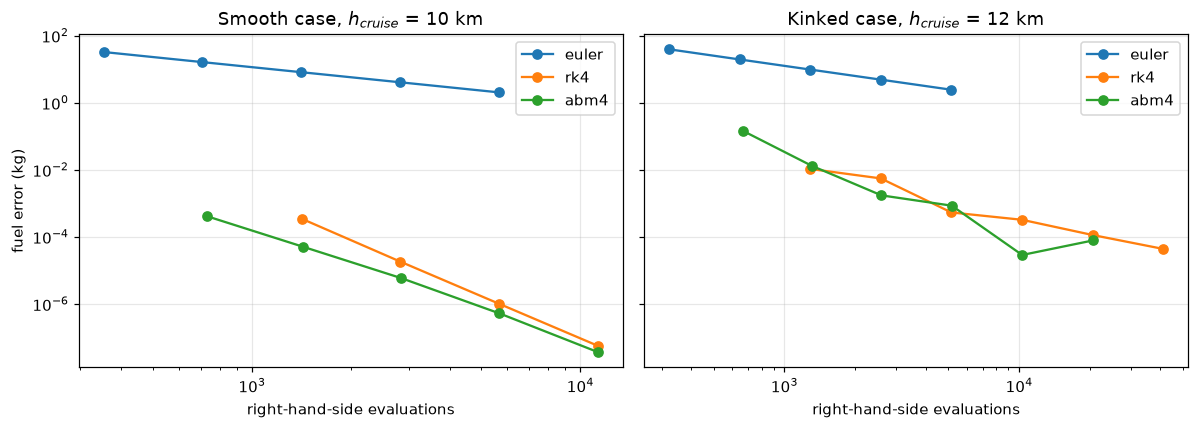

Smooth case, $h_{cruise}$ = 10 km: right-hand-side evaluations needed for a target fuel error  (* = extrapolated beyond measured range)
   target               euler           rk4          abm4
     1e-04 kg   115,126,186*        1,901         1,152  
     1e-05 kg  1,151,654,001*        3,274         2,409  
     1e-06 kg  11,520,462,718*        5,682         4,725  
     1e-07 kg  115,243,867,623*        9,876         8,732  

(The kinked case has irregular, non-monotone errors, so we read it from the plot rather than tabulating it.)


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a_, (key, (hc0, ttl, _)) in zip(ax, CASES.items()):
    for meth, (dts, errs, nf) in DATA[key].items(): a_.loglog(nf, errs, "o-", label=meth)
    a_.set(xlabel="right-hand-side evaluations", title=ttl); a_.legend()
ax[0].set_ylabel("fuel error (kg)"); plt.tight_layout(); plt.show()

def evals_for(err_target, errs, nf):
    # log-log interpolation between measured points; power-law extrapolation outside the measured range
    le, ln = np.log(errs), np.log(nf); order = np.argsort(le); le, ln = le[order], ln[order]
    t = math.log(err_target)
    if le[0] <= t <= le[-1]: return float(np.exp(np.interp(t, le, ln))), False
    i, j = (0, 1) if t < le[0] else (-2, -1)
    return float(np.exp(ln[i] + (ln[j]-ln[i])/(le[j]-le[i])*(t - le[i]))), True

key, ttl = "smooth", CASES["smooth"][1]
print(f"{ttl}: right-hand-side evaluations needed for a target fuel error  (* = extrapolated beyond measured range)")
print("   target      " + "".join(f"{m:>14}" for m in DATA[key]))
for tgt in (1e-4, 1e-5, 1e-6, 1e-7):
    row = []
    for meth, (dts, errs, nf) in DATA[key].items():
        n, ex = evals_for(tgt, errs, nf); row.append(f"{n:12,.0f}{'*' if ex else ' '} ")
    print(f"   {tgt:7.0e} kg  " + "".join(row))
print("\n(The kinked case has irregular, non-monotone errors, so we read it from the plot rather than tabulating it.)")

## 5b. Step sizes for the sweep

Stability caps the usable cruise step (above). For RK4 we use $\Delta t$ = 4 s (climb) / 30 s (cruise) $K\Delta t=1.5$. The PECE pair
needs $K\Delta t<1.29$, so we use 4 s / 20 s ($K\Delta t=1.0$). Check against a fine RK4 reference at the three optimal cases.

In [12]:
import time
cases = [("ORD-JFK", math.radians(3.5), 12000.), ("ORD-CPH", math.radians(3.5), 13000.), ("ORD-HKG", math.radians(3.5), 14000.)]
SETTINGS = {"rk4": (4.0, 30.0), "abm4": (4.0, 20.0)}
print(f"{'route':8s} {'method':6s} {'fuel (kg)':>12s} {'|err| vs fine ref (kg)':>24s} {'rhs evals':>11s} {'wall (s)':>9s}")
for name, g_, h_ in cases:
    Xv = ROUTES[name]; ref = fly(g_, h_, Xv, dt_climb=0.5, dt_cruise=2.0, method="rk4")["fuel"]
    for meth, (dc, dr_) in SETTINGS.items():
        t0 = time.perf_counter(); r = fly(g_, h_, Xv, dt_climb=dc, dt_cruise=dr_, method=meth); wall = time.perf_counter() - t0
        print(f"{name:8s} {meth:6s} {r['fuel']:12.2f} {abs(r['fuel']-ref):24.4f} {r['nfev']:11,d} {wall:9.3f}")

route    method    fuel (kg)   |err| vs fine ref (kg)   rhs evals  wall (s)
ORD-JFK  rk4        24923.72                   0.0025       1,656     0.012
ORD-JFK  abm4       24923.71                   0.0013         980     0.009
ORD-CPH  rk4       101785.46                   0.0014       4,740     0.024
ORD-CPH  abm4      101785.46                   0.0010       3,276     0.021
ORD-HKG  rk4       164639.46                   0.0009       7,860     0.039
ORD-HKG  abm4      164639.46                   0.0009       5,600     0.036


## 6. Parameter sweep — minimum fuel over $(\gamma, h_{cruise})$ for each route
Grey/colored cells are masked; the star marks the minimum-fuel feasible case.

ORD-JFK: min fuel 24.9 t at gamma = 3.5 deg, h_cruise = 12.0 km
ORD-CPH: min fuel 101.8 t at gamma = 3.5 deg, h_cruise = 13.0 km
ORD-HKG: min fuel 164.6 t at gamma = 3.5 deg, h_cruise = 14.0 km


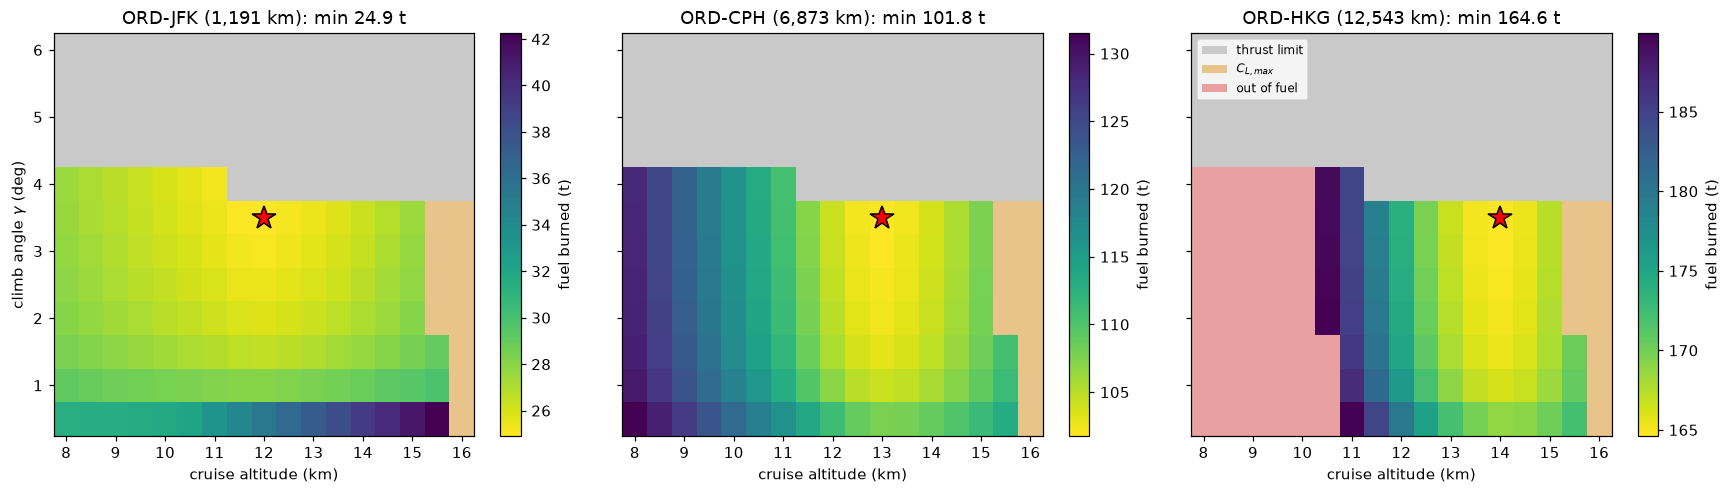

In [13]:
gam = np.arange(0.5, 6.01, 0.5); hcr = np.arange(8000, 16001, 500.)
RES = {}
for name, Xv in ROUTES.items():
    F = np.full((len(gam), len(hcr)), np.nan); Rz = np.zeros((len(gam), len(hcr)), dtype=int)
    for i, g in enumerate(gam):
        for j, hh in enumerate(hcr):
            r = fly(math.radians(g), hh, Xv, dt_climb=4.0, dt_cruise=30.0)
            if r["ok"]: F[i, j] = r["fuel"]
            else: Rz[i, j] = {"thrust": 1, "CLmax": 2, "fuel": 3}.get(r["reason"], 4)
    RES[name] = (F, Rz)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
cat = ListedColormap(["white", "#c9c9c9", "#e8c48a", "#e8a0a0", "#999999"])
for ax, (name, (F, Rz)) in zip(axes, RES.items()):
    ax.pcolormesh(hcr/1e3, gam, Rz, cmap=cat, vmin=0, vmax=4, shading="nearest")
    im = ax.pcolormesh(hcr/1e3, gam, np.ma.masked_invalid(F)/1e3, cmap="viridis_r", shading="nearest")
    i, j = np.unravel_index(np.nanargmin(F), F.shape)
    ax.plot(hcr[j]/1e3, gam[i], "r*", ms=16, mec="k")
    ax.set(xlabel="cruise altitude (km)", title=f"{name} ({ROUTES[name]/1e3:,.0f} km): min {F[i,j]/1e3:.1f} t")
    ax.grid(False); plt.colorbar(im, ax=ax, label="fuel burned (t)")
    print(f"{name}: min fuel {F[i,j]/1e3:.1f} t at gamma = {gam[i]:.1f} deg, h_cruise = {hcr[j]/1e3:.1f} km")
axes[0].set_ylabel(r"climb angle $\gamma$ (deg)")
axes[2].legend(handles=[Patch(fc="#c9c9c9", label="thrust limit"), Patch(fc="#e8c48a", label=r"$C_{L,max}$"), Patch(fc="#e8a0a0", label="out of fuel")], loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

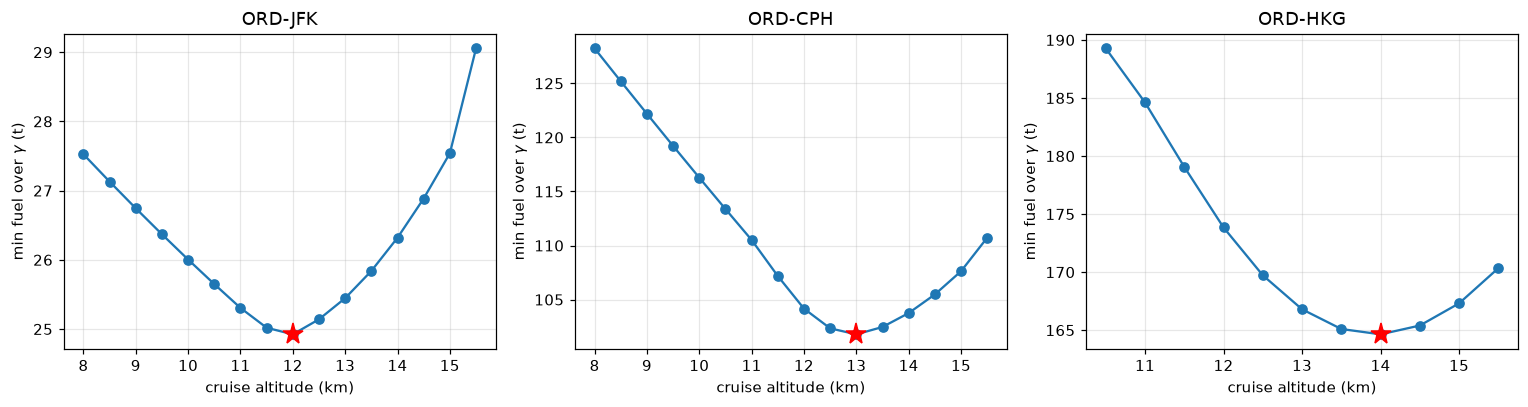

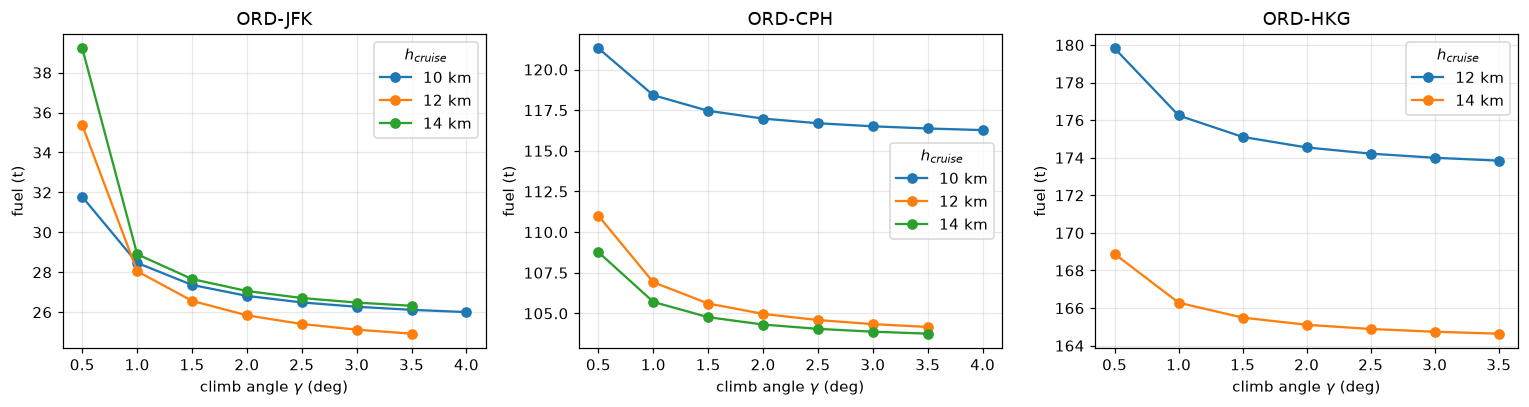

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a_, (name, (F, Rz)) in zip(ax, RES.items()):
    best = np.nanmin(np.where(np.isfinite(F), F, np.inf), axis=0); best[~np.isfinite(best)] = np.nan
    a_.plot(hcr/1e3, best/1e3, "o-"); a_.set(xlabel="cruise altitude (km)", ylabel="min fuel over $\\gamma$ (t)", title=name)
    j = np.nanargmin(best); a_.plot(hcr[j]/1e3, best[j]/1e3, "r*", ms=14)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a_, (name, (F, Rz)) in zip(ax, RES.items()):
    for hsel in (10000., 12000., 14000.):
        j = int(np.argmin(abs(hcr-hsel))); col = F[:, j]/1e3
        if np.isfinite(col).any(): a_.plot(gam, col, "o-", label=f"{hsel/1e3:.0f} km")
    a_.set(xlabel=r"climb angle $\gamma$ (deg)", ylabel="fuel (t)", title=name); a_.legend(title=r"$h_{cruise}$")
plt.tight_layout(); plt.show()

## 7. Optimal trajectories

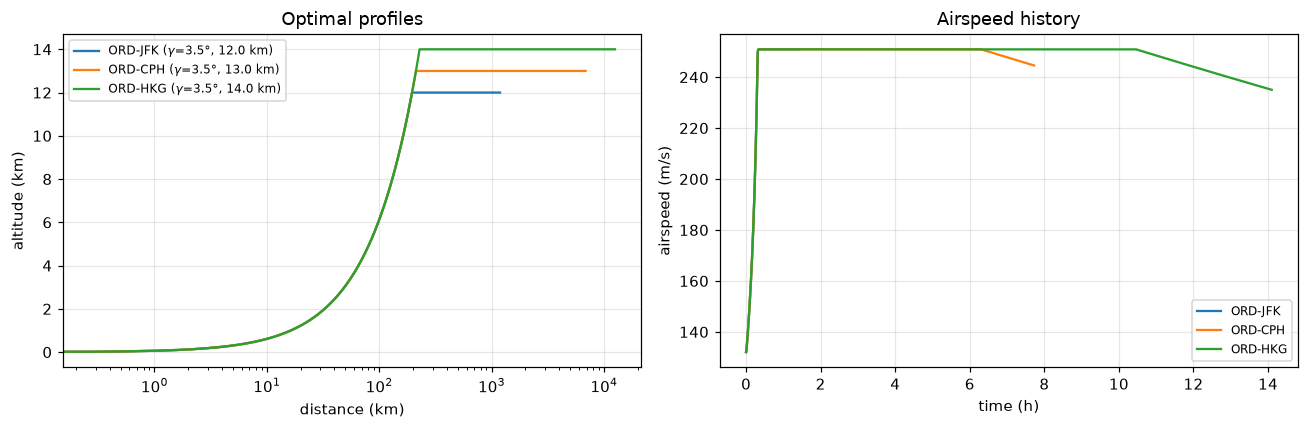

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, (F, Rz) in RES.items():
    i, j = np.unravel_index(np.nanargmin(F), F.shape)
    r = fly(math.radians(gam[i]), hcr[j], ROUTES[name], dt_climb=2.0, dt_cruise=20.0, record=True)
    H = np.array(r["hist"]); t, V_, h_, x_, m_ = H.T
    ax[0].plot(x_/1e3, h_/1e3, label=f"{name} ($\\gamma$={gam[i]:.1f}°, {hcr[j]/1e3:.1f} km)")
    ax[1].plot(t/3600, V_, label=name)
ax[0].set(xlabel="distance (km)", ylabel="altitude (km)", title="Optimal profiles"); ax[0].set_xscale("log"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="time (h)", ylabel="airspeed (m/s)", title="Airspeed history"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()